<a href="https://colab.research.google.com/github/SolodovnikA/backend-summer/blob/develop/credit_card_analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Credit Card Customer Analytics

Why do credit card customers leave, and which signals show it early?

Dataset: [Credit Card Customers (BankChurners)](https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers), ~10k customers of a bank (loaded from a GitHub mirror of the original Kaggle file).

Tools: SQL (DuckDB), Python (pandas).

## 0. Setup

In [2]:
!pip install -q duckdb
import duckdb
import pandas as pd

In [3]:
# Mirror of the Kaggle dataset (Kaggle is not reachable from Russia)
URL = 'https://raw.githubusercontent.com/lyesds/churn_prediction/main/data/BankChurners.csv'
df = pd.read_csv(URL)
# the last two columns are leftovers from someone else's model, we don't need them
df = df.loc[:, ~df.columns.str.startswith('Naive_Bayes')]

con = duckdb.connect()
con.register('customers', df)

def q(sql):
    """Run a SQL query and show the result as a table."""
    return con.sql(sql).df()

print(df.shape)

(10127, 21)


### Warm-up: look at the data

In [4]:
q("""
SELECT *
FROM customers
LIMIT 5
""")

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000


## 1. Churn overview

`Attrition_Flag` is either `'Existing Customer'` or `'Attrited Customer'` (left the bank).

**1.1** How many customers are there in total, and what share of them left?

In [5]:
q("""
SELECT COUNT(*) AS total_customers,
       ROUND(AVG(CASE WHEN Attrition_Flag = 'Attrited Customer' THEN 1 ELSE 0 END)* 100, 1) AS churn_pct
FROM customers
""")

,total_customers,churn_pct
0,10127,16.1


**1.2** Churn rate by card type (`Card_Category`).

In [6]:
q("""
SELECT Card_Category,
COUNT(*) AS customers,
ROUND(AVG(CASE WHEN Attrition_Flag = 'Attrited Customer' THEN 1 ELSE 0 END) * 100, 1) AS churn_pct
FROM customers
GROUP BY Card_Category
ORDER BY churn_pct DESC
""")

,Card_Category,customers,churn_pct
0,Platinum,20,25.0
1,Gold,116,18.1
2,Blue,9436,16.1
3,Silver,555,14.8


**1.3** Churn rate by income group (`Income_Category`), sorted from highest to lowest churn.

In [7]:
q("""
SELECT Income_Category,
COUNT(*) AS customers,
ROUND(AVG(CASE WHEN Attrition_Flag = 'Attrited Customer' THEN 1 ELSE 0 END) * 100, 1) AS churn_pct
FROM customers
GROUP BY Income_Category
ORDER BY churn_pct DESC
""")

,Income_Category,customers,churn_pct
0,$120K +,727,17.3
1,Less than $40K,3561,17.2
2,Unknown,1112,16.8
3,$80K - $120K,1535,15.8
4,$40K - $60K,1790,15.1
5,$60K - $80K,1402,13.5


**1.4** Average number of transactions per year (`Total_Trans_Ct`) for customers who left vs. stayed.

In [8]:
q("""
SELECT Attrition_Flag,
COUNT(*) AS customers,
ROUND(AVG(Total_Trans_Ct), 1) AS avg_transactions
FROM customers
GROUP BY Attrition_Flag
ORDER BY avg_transactions
""")

,Attrition_Flag,customers,avg_transactions
0,Attrited Customer,1627,44.9
1,Existing Customer,8500,68.7


**1.5** Churn rate for customers inactive 3+ months (`Months_Inactive_12_mon`) vs. everyone else.

In [9]:
q("""
SELECT CASE WHEN Months_Inactive_12_mon >= 3 THEN '3+ months' ELSE 'less than 3 months' END AS inactivity,
COUNT(*) AS customers,
ROUND(AVG(CASE WHEN Attrition_Flag = 'Attrited Customer' THEN 1 ELSE 0 END) * 100, 1) AS churn_pct
FROM customers
GROUP BY inactivity
""")

,inactivity,customers,churn_pct
0,3+ months,4583,22.0
1,less than 3 months,5544,11.2


### Notes: what I see so far

- Overall churn: 16.1% (1,627 of 10,127 customers).
- Card type and income barely explain churn: differences of 2–4 p.p., and the
  extreme groups are tiny (only 20 Platinum customers). 11% of customers have
  unknown income.
- Activity is what matters. Customers who left made ~45 transactions a year vs.
  ~69 for those who stayed (about a third fewer).
- Customers inactive for 3+ months churn twice as often: 22.0% vs. 11.2%.
- Hypothesis: falling activity is an early warning signal of churn. This is a
  correlation, not proven causation.
  


## 2. Where does the risk start?

**2.1 Churn by months of inactivity**


In [10]:
q("""
SELECT Months_Inactive_12_mon,
COUNT(*) AS customers,
ROUND(AVG(CASE WHEN Attrition_Flag = 'Attrited Customer' THEN 1 ELSE 0 END) * 100, 1) AS churn_pct
FROM customers
GROUP BY Months_Inactive_12_mon
ORDER BY Months_Inactive_12_mon
""")

,Months_Inactive_12_mon,customers,churn_pct
0,0,29,51.7
1,1,2233,4.5
2,2,3282,15.4
3,3,3846,21.5
4,4,435,29.9
5,5,178,18.0
6,6,124,15.3


**Takeaway:**

- Churn grows steadily with each inactive month: 4.5% (1 month) → 15.4% → 21.5%
  → 29.9% (4 months). Months 2–3 look like the right moment to step in.
- Customers inactive 5–6 months churn less (18%, 15%): possibly "dormant"
  customers who stop using the card without closing it. Hypothesis only.
- The 0-month group (51.7%) has only 29 customers, too small to interpret.


**2.2 Churn by number of transactions**

In [11]:
q("""
SELECT MIN(Total_Trans_Ct) AS min_tx,
MAX(Total_Trans_ct) AS max_tx
FROM customers
""")


,min_tx,max_tx
0,10,139


In [12]:
q("""
SELECT CASE WHEN Total_Trans_Ct < 40 THEN '1) < 40'
WHEN Total_Trans_Ct < 60 THEN '2) 40-59'
WHEN Total_Trans_Ct < 80 THEN '3) 60-79'
ELSE '4) 80+'
END AS tx_group,
COUNT(*) AS customers,
ROUND(AVG(CASE WHEN Attrition_Flag = 'Attrited Customer' THEN 1 ELSE 0 END) * 100, 1) AS churn_pct
FROM customers
GROUP BY tx_group
ORDER BY tx_group
""")

,tx_group,customers,churn_pct
0,1) < 40,1802,30.1
1,2) 40-59,2134,39.1
2,3) 60-79,3468,6.2
3,4) 80+,2723,1.3


**Takeaway:** Churn falls off a cliff above ~60 transactions a year (about 5 a month): 30–39% below it, 6.2% for 60–79 and just 1.3% for 80+. Unexpectedly, customers with fewer than 40 transactions churn less than those with 40–59 (30.1% vs 39.1%). They may be a different segment, such as “just in case” cardholders. To check later with transaction amounts.

**2.3. Churn by contacts with the bank**

In [13]:
q("""
SELECT Contacts_Count_12_mon,
COUNT(*) AS customers,
ROUND(AVG(CASE WHEN Attrition_Flag = 'Attrited Customer' THEN 1 ELSE 0 END) * 100, 1) AS churn_pct
FROM customers
GROUP BY Contacts_Count_12_mon
ORDER BY Contacts_Count_12_mon
""")

,Contacts_Count_12_mon,customers,churn_pct
0,0,399,1.8
1,1,1499,7.2
2,2,3227,12.5
3,3,3380,20.1
4,4,1392,22.6
5,5,176,33.5
6,6,54,100.0


**Takeaway:** Churn rises with every contact with the bank: 1.8% with no contacts, 12.5% with 2, 33.5% with 5, and all 54 customers with 6 contacts left (100%). A perfect 100% is a warning sign: if contacts include calls to close the account, this metric partly records churn itself rather than predicting it (possible data leakage). We need to know what counts as a contact and when it happened before using it as an early signal.

**2.4. Chart: churn by activity**

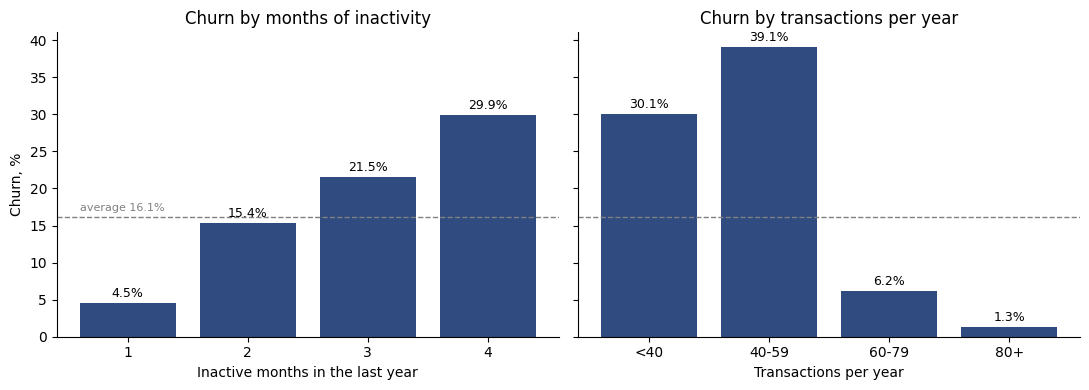

In [16]:
import matplotlib.pyplot as plt

churn = "ROUND(AVG(CASE WHEN Attrition_Flag = 'Attrited Customer' THEN 1 ELSE 0 END) * 100, 1) AS churn_pct"

inactive = q(f"""
SELECT Months_Inactive_12_mon AS months, COUNT(*) AS customers, {churn}
             FROM customers
             WHERE Months_Inactive_12_mon BETWEEN 1 AND 4
             GROUP BY months ORDER BY months
""")

tx = q(f"""
SELECT CASE WHEN Total_Trans_Ct < 40 THEN '<40'
WHEN Total_Trans_Ct < 60 THEN '40-59'
WHEN Total_Trans_Ct < 80 THEN '60-79'
ELSE '80+' END AS tx_group,
MIN(Total_Trans_Ct) AS sort_key, {churn}
       FROM customers
       GROUP BY tx_group ORDER BY sort_key
""")

fig, axes = plt.subplots(1, 2, figsize = (11, 4), sharey = True)
axes[0].bar(inactive['months'].astype(str), inactive['churn_pct'], color = '#2f4b80')
axes[0].set_title('Churn by months of inactivity')
axes[0].set_xlabel('Inactive months in the last year')
axes[0].set_ylabel('Churn, %')

axes[1].bar(tx['tx_group'], tx['churn_pct'], color = '#2f4b80')
axes[1].set_title('Churn by transactions per year')
axes[1].set_xlabel('Transactions per year')

for ax, data in [(axes[0], inactive), (axes[1], tx)]:
  for i, v in enumerate(data['churn_pct']):
    ax.text(i,v + 0.8, f'{v}%', ha = 'center', fontsize = 9)
  ax.axhline(16.1, color = 'grey', linestyle = '--', linewidth = 1)
  ax.spines[['top', 'right']].set_visible(False)

axes[0].text(-0.4, 17, 'average 16.1%', color = 'grey', fontsize = 8, ha = 'left')
plt.tight_layout()
plt.show()

**Takeaway:** Both charts tell the same story: churn is driven by how actively the card is used. Risk climbs with every inactive month and drops sharply once a customer makes 60+ transactions a year.

### Block 2 summary:

- Inactivity: churn grows from 4.5% (1 inactive month) to 29.9% (4 months).
  Months 2–3 look like the right moment for a retention offer.
- Transactions: below ~60 a year churn is 30–39%; above it, 6% or less.
  60 transactions a year (about 5 a month) works as a simple threshold.
- Contacts with the bank: churn rises with every contact and reaches 100% at 6.
  This may partly be churn itself (calls to close the account), so it needs
  checking before use as an early signal.
- Open question: customers with fewer than 40 transactions churn less than
  those with 40–59. Possibly a different segment, to check in block 3.